Escanea el mercado y trae los tickers cuyo precio este N% de su média móvil ponderada de 150 y 200 en SEMANAL.
Correr sábado o domingo: todas las barras son semanas cerradas

In [8]:
#Importa las librerias y módulos necesarios.
%load_ext autoreload
%autoreload 2
import pandas as pd
from datos import obtener_tickers

# Importa las librerias para gráficar.

import matplotlib.pyplot as plt
import math

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
# Descarga de datos semanales.

data_7d = obtener_tickers("1wk", "max")

Se han cargado 273 tickers...
Tiempo de descarga en 10212.12 segundos.
Se descargó datos en temporalidad 1wk con un periodo de max


In [ ]:
resultados = []

for ticker in data_7d.columns.get_level_values(0).unique():
    df_ticker = data_7d[ticker].dropna(subset=['Close', 'High', 'Low'])
    # Descartar la vela semanal en curso
    df_ticker = df_ticker.iloc[:-1]
    
    if len(df_ticker) >= 600:
        cierre = df_ticker['Close']
        high = df_ticker['High']
        
        s_ema_150 = cierre.ewm(span=150, adjust=False).mean()
        s_ema_200 = cierre.ewm(span=200, adjust=False).mean()
        
        ema_150 = s_ema_150.iloc[-1].item()
        ema_200 = s_ema_200.iloc[-1].item()
        precio = cierre.iloc[-1].item()

        # Condición 1: Estructura alcista y pendiente positiva en ambas medias
        pendiente_150 = ema_150 > s_ema_150.iloc[-14].item()
        pendiente_200 = ema_200 > s_ema_200.iloc[-14].item()
        estructura_valida = (ema_150 > ema_200) and pendiente_150 and pendiente_200

        if estructura_valida:
            dist_150 = ((precio - ema_150) / ema_150) * 100
            dist_200 = ((precio - ema_200) / ema_200) * 100

            # Condición 2: El precio está tocando la zona de la EMA (a 1,5% de margen)
            toque_150 = abs(dist_150) <= 1.5
            toque_200 = abs(dist_200) <= 1.5

            # Condición 3: (Antirrebote de techo)
            max_previo_150 = high.iloc[-8:-1].max() > (ema_150 * 1.03)
            max_previo_200 = high.iloc[-8:-1].max() > (ema_200 * 1.03)

            soportes_validos = (toque_150 and max_previo_150) or (toque_200 and max_previo_200)

            if soportes_validos:
                resultados.append({
                    'ticker': ticker,
                    'precio': precio,
                    'dist_150': dist_150,
                    'dist_200': dist_200,
                    'df_plot': df_ticker.iloc[-104:].copy(),
                    'ema_150_plot': s_ema_150.iloc[-104:].copy(),
                    'ema_200_plot': s_ema_200.iloc[-104:].copy()
                })

In [11]:
# Print output de los resultados.

for r in resultados:
    print(
        f"SOPORTE | Ticker: {r['ticker']} | Precio: {r['precio']:.2f} | "
        f"Dist. EMA 150: {r['dist_150']:.2f}% | Dist. EMA 200: {r['dist_200']:.2f}%"
    )

SOPORTE | Ticker: VALE | Precio: 11.59 | Dist. EMA 150: -2.64% | Dist. EMA 200: 1.47%
SOPORTE | Ticker: SRE | Precio: 78.17 | Dist. EMA 150: -2.51% | Dist. EMA 200: 0.96%
SOPORTE | Ticker: ICLN | Precio: 16.45 | Dist. EMA 150: 1.01% | Dist. EMA 200: 2.50%
SOPORTE | Ticker: NOC | Precio: 525.01 | Dist. EMA 150: 0.18% | Dist. EMA 200: 4.26%
SOPORTE | Ticker: BKNG | Precio: 160.67 | Dist. EMA 150: -6.19% | Dist. EMA 200: -1.00%
SOPORTE | Ticker: CAT | Precio: 558.63 | Dist. EMA 150: 1.41% | Dist. EMA 200: 13.24%
SOPORTE | Ticker: INTC | Precio: 56.28 | Dist. EMA 150: 1.19% | Dist. EMA 200: 9.91%
SOPORTE | Ticker: BTC-USD | Precio: 74584.65 | Dist. EMA 150: -0.24% | Dist. EMA 200: 6.95%


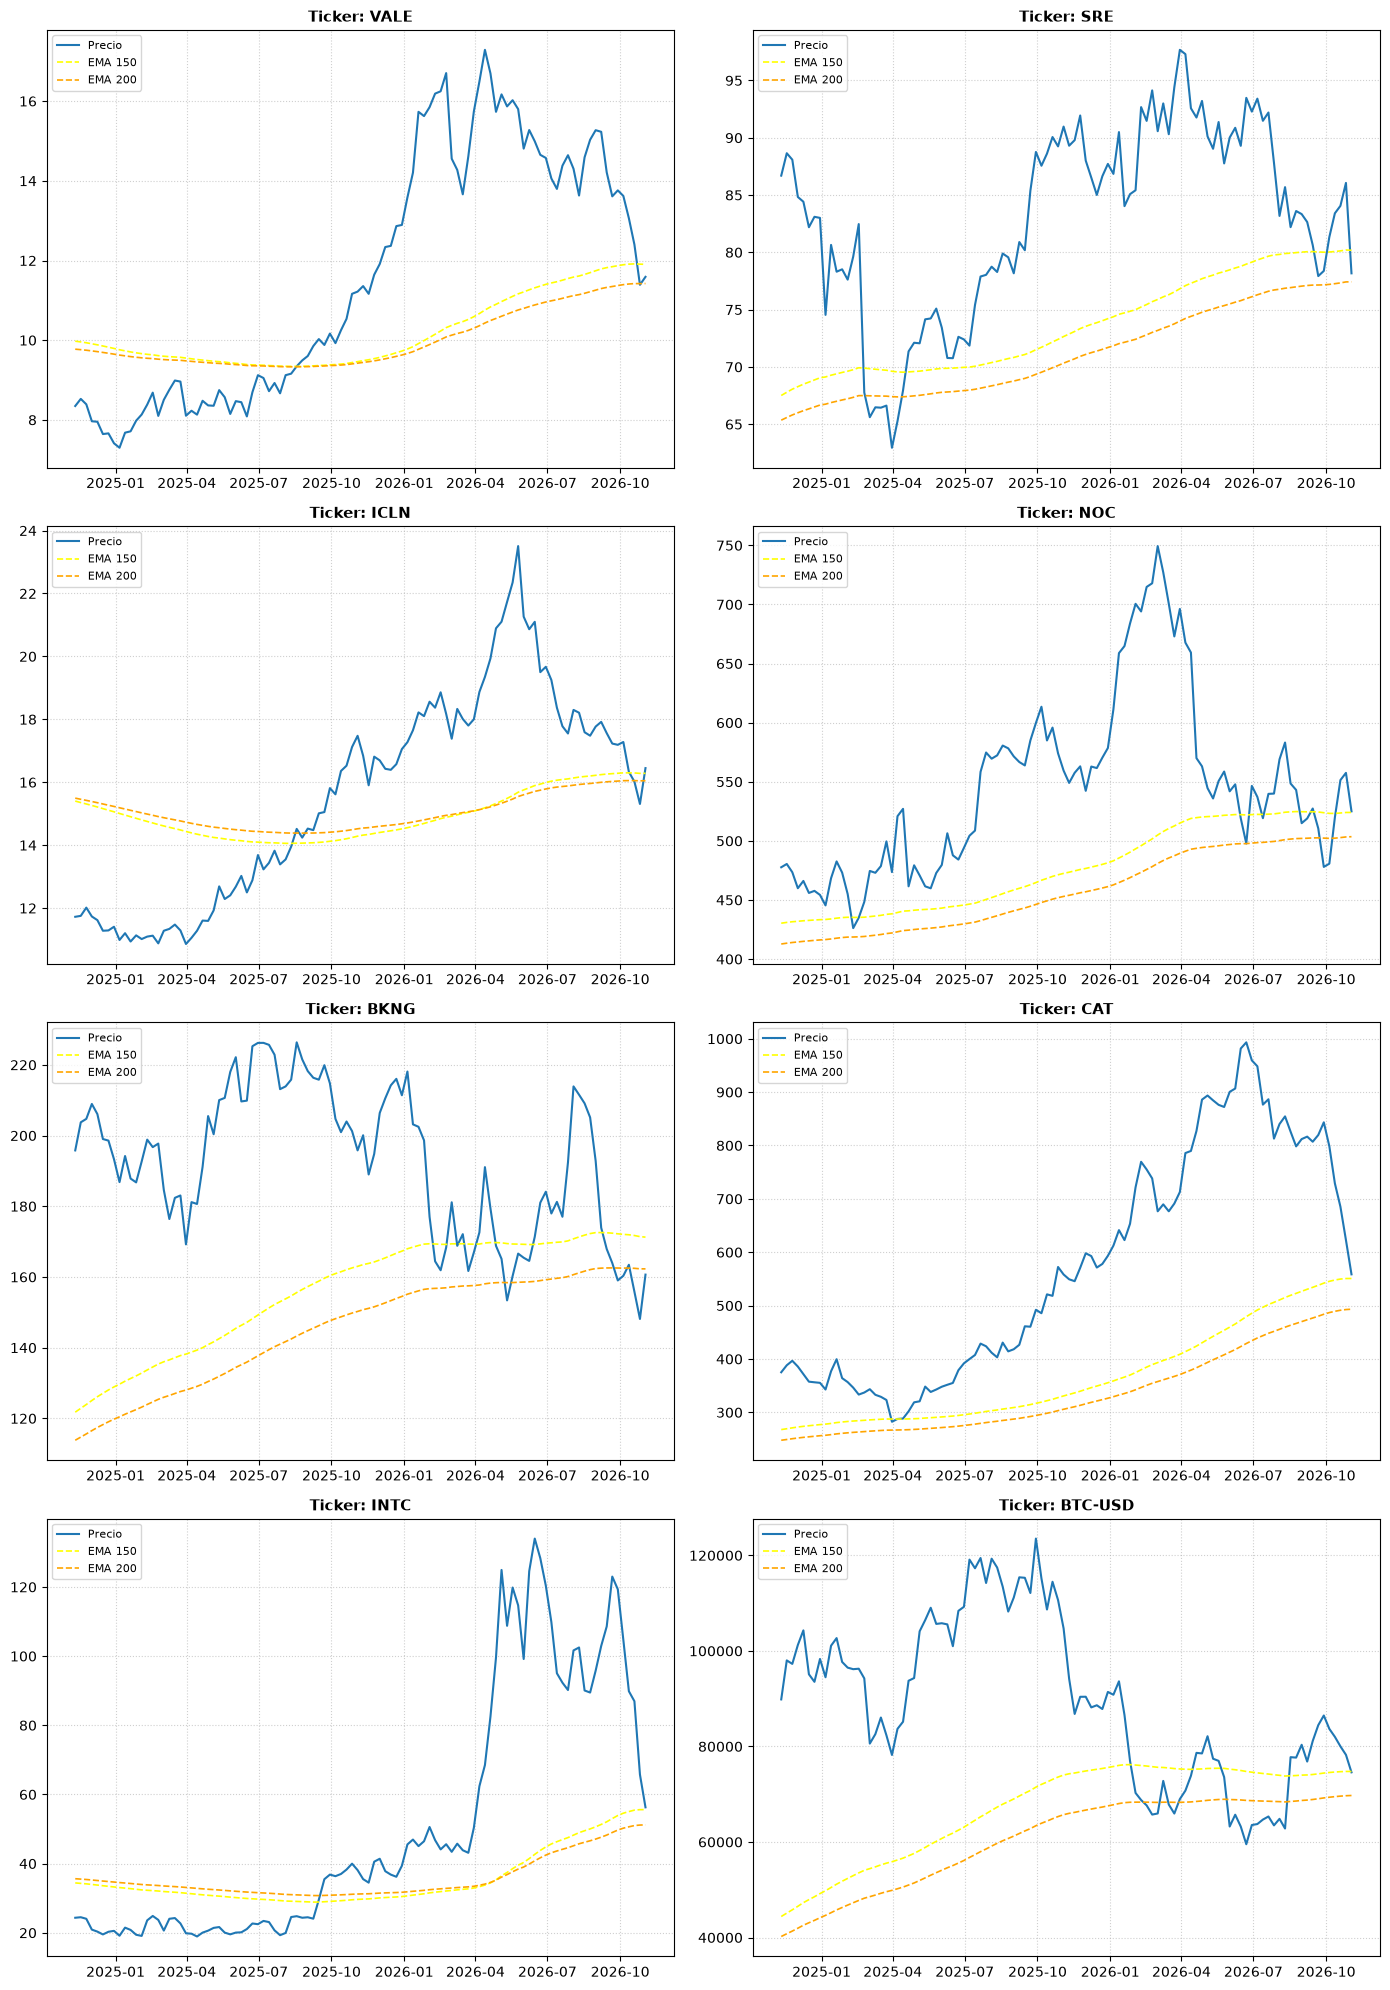

In [12]:
# Plotea los activos candidatos.

n_activos = len(resultados)
if n_activos > 0:
    cols = 2 if n_activos > 1 else 1
    rows = math.ceil(n_activos / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows), squeeze=False)
    axes_flat = axes.flatten()
    
    for i, r in enumerate(resultados):
        ax = axes_flat[i]
        df_p = r['df_plot']
        c_p = df_p['Close']
        
        ax.plot(df_p.index, c_p, label='Precio', color='#1f77b4', linewidth=1.5)
        ax.plot(df_p.index, r['ema_150_plot'], label='EMA 150', color='yellow', linestyle='--', linewidth=1.2)
        ax.plot(df_p.index, r['ema_200_plot'], label='EMA 200', color='orange', linestyle='--', linewidth=1.2)
        
        ax.set_title(f"Ticker: {r['ticker']}", fontsize=11, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper left', fontsize=8)

    for j in range(i + 1, len(axes_flat)):
        fig.delaxes(axes_flat[j])
        
    plt.tight_layout()
    plt.show()
else:
    print("Sin activos válidos para graficar.")